# INF201 - Deliverable 1 - Sample solution

This is a sample solution for the 1st deliverable in INF201 (2026).
Written by Turid Torheim, NMBU. Gemini was used when writing this document, in particular to help design the plots.

Code based on this example: [Frost's Python user guide](https://frost.met.no/python_example.html)

## Set up utility functions

In [26]:
import matplotlib.dates as mdates
from matplotlib import pyplot as plt
import pandas as pd
import requests


def collect_data(endpoint: str, parameter_dict: dict, client_id: str) -> dict:
    """Function for getting data from frost.met.no using specified parameters and id"""

    # Issue HTTP GET request
    r = requests.get(endpoint, parameter_dict, auth=(client_id, ''))

    # Extract JSON data
    r_payload = r.json()

    # Check if the request worked, print out any errors
    if r.status_code == 200:
        print('Data retrieved from frost.met.no!')
    else:
        print(f'Error! Returned status code {r.status_code}')
        print(f'Message: {r_payload['error']['message']}')
        print(f'Reason: {r_payload['error']['reason']}')
        return {}

    return r_payload


def payload_to_df(payload: dict) -> pd.DataFrame:
    """Create dataframe to be used for plots and summary tables"""

    # Here I show two possible solutions, as alternatives to the one suggested
    # in the frost.met.no example script

    # METHOD 1: Create dictionaries that are then converted to DataFrame
    # Note: Use the first time offset (index 0) by default
    records = [
        {"time": entry["referenceTime"], "value": entry["observations"][0]["value"]}
        for entry in payload["data"]
        if entry.get("observations")  # Guards against empty observation lists
    ]
    # Create DataFrame, convert "time" to datetime and set as index
    df = pd.DataFrame(records)
    df["time"] = pd.to_datetime(df["time"])
    df.set_index("time", inplace=True)

    # # METHOD 2: Use Pandas function for converting json data to DataFrame
    # # Here we do not select which time offset to use, so that would have to be done afterwards
    # df = pd.json_normalize(
    #     payload["data"],
    #     record_path="observations",
    #     meta=["referenceTime"]
    # )
    # # Convert "time" to datetime and set as index
    # df["time"] = pd.to_datetime(df["referenceTime"])
    # df = df.set_index("time")[["value"]]

    return df



## Read ID and define parameters

In [27]:
# Read client_id from file
client_id = open('../../../frost_credentials.txt').read().strip()

# Define endpoint
endpoint = "https://frost.met.no/observations/v0.jsonld"

# Define parameters for the different tasks
parameters_temp_2025_mean = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2026-01-01",
    }
parameters_prec_2025_mean = {
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D)",
    "referencetime": "2025-01-01/2026-01-01",
}
parameters_temp_1925_mean = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "1925-01-01/1926-01-01",
    }
parameters_temp_2025_max = {
    "sources": "SN17850",
    "elements": "max(air_temperature P1D)",
    "referencetime": "2025-01-01/2026-01-01",
    }

## Task 1 - Temperatures in 2025
Get the data from frost.met.no, plot them and create a summary table.

In [28]:
# Task 1: 2025 temperatures

# Request data from frost.met.no
payload_temp_2025_mean = collect_data(endpoint, parameters_temp_2025_mean, client_id)

# Create dataframe with timestamp as index and temperature as the only value
# Also rename the column to "mean_temp" for clarity
df_temp_2025_mean = payload_to_df(payload_temp_2025_mean)
df_temp_2025_mean.rename(columns={"value": "mean_temp"}, inplace=True)


Data retrieved from frost.met.no!


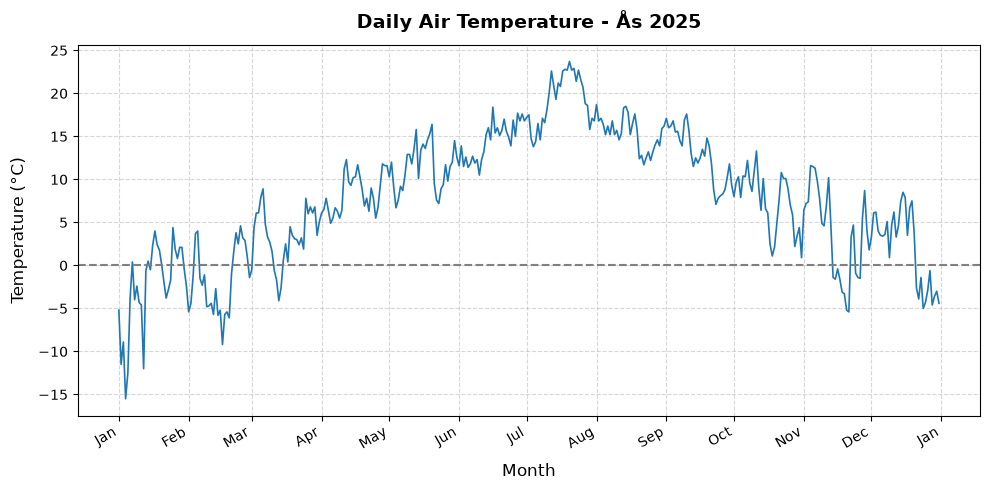

In [29]:
# Create nicely formatted temperature plot

# Set up figure for plotting
fig, ax = plt.subplots(figsize=(10, 5), dpi=100)

# Create line plot
ax.plot(df_temp_2025_mean.index, df_temp_2025_mean["mean_temp"], linewidth=1.2)

# Format x-axis to show months
ax.xaxis.set_major_locator(mdates.MonthLocator())  # Major tick at every month start
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))  # Jan, Feb, etc.

# Set title and axis labels
ax.set_title("Daily Air Temperature - Ås 2025", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Month", fontsize=12, labelpad=8)
ax.set_ylabel("Temperature (°C)", fontsize=12, labelpad=8)

# Include a horisontal line for temp = 0 degrees Celsius for readability
ax.axhline(y=0, color='gray', linestyle='--')

# Add grid to make the figure easier to read
ax.grid(True, linestyle="--", alpha=0.5)
# Rotate month labels to make them easier to read
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [30]:
# Create a summary table

stats = {
    "Mean": df_temp_2025_mean["mean_temp"].mean(),
    "Median": df_temp_2025_mean["mean_temp"].median(),
    "Min": df_temp_2025_mean["mean_temp"].min(),
    "Max": df_temp_2025_mean["mean_temp"].max(),
}

print("Temperature summary - Ås 2025")
print("\n+------------+------------+")
print("| Metric     | Value (°C) |")
print("+------------+------------+")
for metric, val in stats.items():
    print(f"| {metric:<10} | {val:>10.2f} |")
print("+------------+------------+")

Temperature summary - Ås 2025

+------------+------------+
| Metric     | Value (°C) |
+------------+------------+
| Mean       |       7.87 |
| Median     |       8.30 |
| Min        |     -15.50 |
| Max        |      23.70 |
+------------+------------+


## Task 2: Precipitation in 2025
Get the data from frost.met.no and plot precipitation and temperature together in the same figure.

In [31]:
# Request data and create dataframe
payload_prec_2025_mean = collect_data(endpoint, parameters_prec_2025_mean, client_id)

# Create dataframe with timestamp as index and precipitation as the only value
# Also rename the column to "mean_temp" for clarity
df_prec_2025_mean = payload_to_df(payload_prec_2025_mean)
df_prec_2025_mean.rename(columns={"value": "mean_prec"}, inplace=True)

Data retrieved from frost.met.no!


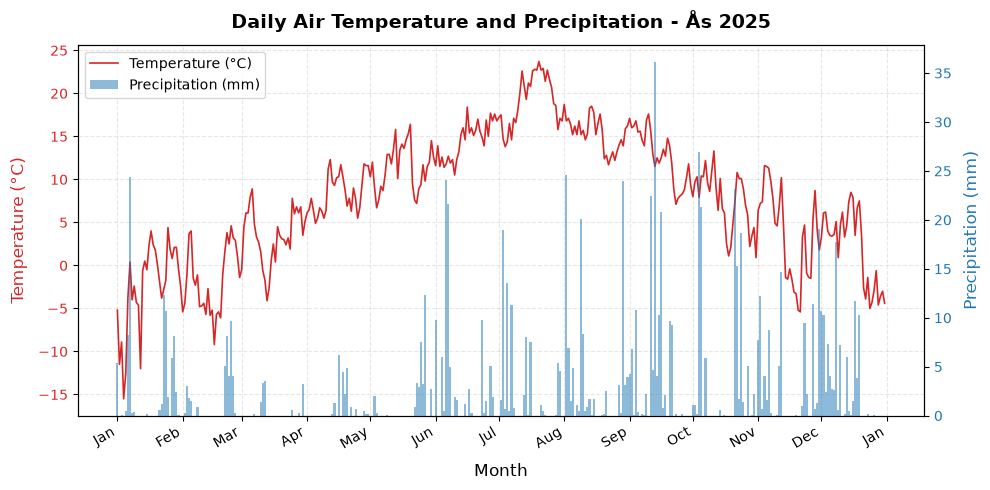

In [32]:
# Create nicely formatted plot of temperature and precipitation

# Set up figure for plotting
fig, ax1 = plt.subplots(figsize=(10, 5), dpi=100)

# Define colours (red for temperature, blue for precipitation)
colour_temp = "#d62728"
colour_prec = "#1f77b4"

# Temperature line plot (will show on left y-axis)
ax1.plot(
    df_temp_2025_mean.index,
    df_temp_2025_mean["mean_temp"],
    color=colour_temp,
    linewidth=1.2,
    label="Temperature (°C)"
)
ax1.set_xlabel("Month", fontsize=12, labelpad=8)
ax1.set_ylabel("Temperature (°C)", color=colour_temp, fontsize=12, labelpad=8)
ax1.tick_params(axis="y", labelcolor=colour_temp)

# Precipitation bar chart (will show on right y-axis)
ax2 = ax1.twinx()
ax2.bar(
    df_prec_2025_mean.index,
    df_prec_2025_mean["mean_prec"],
    color=colour_prec,
    alpha=0.5,
    width=1.0,
    label="Precipitation (mm)"
)
ax2.set_ylabel("Precipitation (mm)", color=colour_prec, fontsize=12, labelpad=8)
ax2.tick_params(axis="y", labelcolor=colour_prec)

# Format x-axis to show months
ax1.xaxis.set_major_locator(mdates.MonthLocator())  # Major tick at every month start
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b"))  # Jan, Feb, etc.

# Set titles, layout, and combined legend
ax1.set_title("Daily Air Temperature and Precipitation - Ås 2025", fontsize=14, fontweight="bold", pad=12)
ax1.grid(True, linestyle="--", alpha=0.3)
fig.autofmt_xdate()

# Combine handles and labels from both axes into a single legend
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(handles1 + handles2, labels1 + labels2, loc="upper left")

plt.tight_layout()
plt.show()

# Task 3: 1925 temperatures


In [33]:
# Request data and create dataframe
payload_temp_1925_mean = collect_data(endpoint, parameters_temp_1925_mean, client_id)

# Collect time stamps (as datetime objects) and the relevant temperatures
df_temp_1925_mean = payload_to_df(payload_temp_1925_mean)
df_temp_1925_mean.rename(columns={"value": "mean_temp"}, inplace=True)

Data retrieved from frost.met.no!


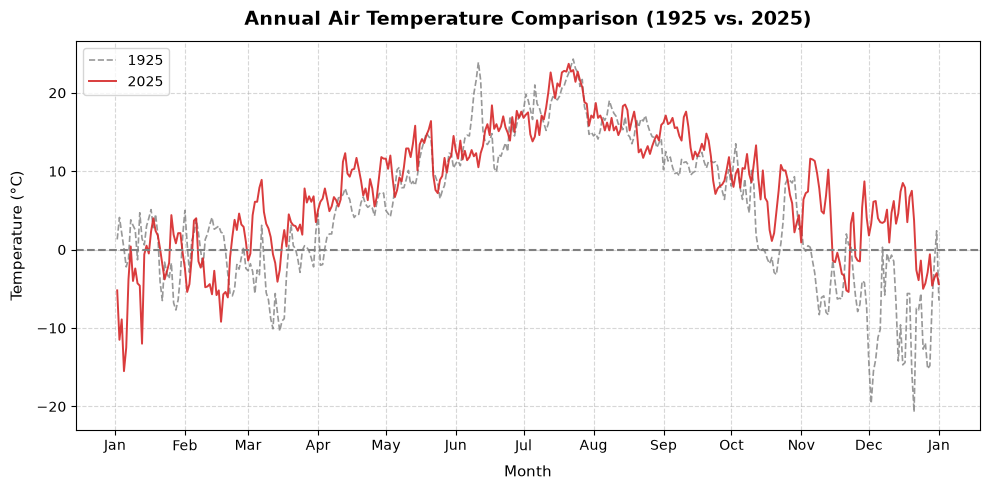

In [34]:
# Create nicely formatted plot combining 1925 and 2025 temperatures

# Set up figure for plotting
fig, ax = plt.subplots(figsize=(10, 5), dpi=100)

# Align x-axes by day of year so the annual curves overlay directly
ax.plot(
    df_temp_1925_mean.index.dayofyear,
    df_temp_1925_mean["mean_temp"],
    color="#7f7f7f",
    linestyle="--",
    linewidth=1.2,
    alpha=0.8,
    label="1925"
)

ax.plot(
    df_temp_2025_mean.index.dayofyear,
    df_temp_2025_mean["mean_temp"],
    color="#d62728",
    linestyle="-",
    linewidth=1.4,
    alpha=0.9,
    label="2025"
)

# Include a horisontal line for temp = 0 degrees Celsius for readability
ax.axhline(y=0, color='gray', linestyle='--')

# Format x-axis to show months
ax.xaxis.set_major_locator(mdates.MonthLocator())  # Major tick at every month start
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))  # Jan, Feb, etc.

# Set title and labels
ax.set_title("Annual Air Temperature Comparison (1925 vs. 2025)", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Month", fontsize=11, labelpad=8)
ax.set_ylabel("Temperature (°C)", fontsize=11, labelpad=8)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

In [35]:
# Create summary of the two years and compare them

summary_df = pd.DataFrame(
    {
        "2025": [
            df_temp_2025_mean["mean_temp"].mean(),
            df_temp_2025_mean["mean_temp"].median(),
            df_temp_2025_mean["mean_temp"].min(),
            df_temp_2025_mean["mean_temp"].max(),
        ],
        "1925": [
            df_temp_1925_mean["mean_temp"].mean(),
            df_temp_1925_mean["mean_temp"].median(),
            df_temp_1925_mean["mean_temp"].min(),
            df_temp_1925_mean["mean_temp"].max(),
        ],
    },
    index=["mean", "median", "min", "max"],
)

# Add difference column for easier comparison
summary_df["Difference (°C)"] = summary_df["2025"] - summary_df["1925"]

print("=== Temperature Comparison Summary ===")
print(summary_df.round(2).to_string())
print("=" * 38)

=== Temperature Comparison Summary ===
         2025   1925  Difference (°C)
mean     7.87   5.28             2.59
median   8.30   5.30             3.00
min    -15.50 -20.70             5.20
max     23.70  24.30            -0.60


## Task 4 - Identify heatwaves - Ås 2025

In [36]:
# Request data (max temperatures for 2025) and create dataframe
payload_temp_2025_max = collect_data(endpoint, parameters_temp_2025_max, client_id)

# Collect time stamps (as datetime objects) and the relevant temperatures
df_temp_2025_max = payload_to_df(payload_temp_2025_max)
df_temp_2025_max.rename(columns={"value": "max_temp"}, inplace=True)

Data retrieved from frost.met.no!


In [37]:
import yaml


def detect_and_export_heatwaves(
    df: pd.DataFrame,
    station_id: str,
    station_name: str,
    year: int,
    threshold: float = 27.0,
    min_days: int = 5,
    output_filename: str = "heatwaves.yml"
) -> None:
    """
    Identifies heatwave periods (at least `min_days` consecutive days >= threshold)
    for a given year and exports a summary to a YAML file.
    """
    # Filter dataset for the specific year (in case the dataset contains data from multiple years)
    df_year = df[df.index.year == year]

    # Filter days meeting or exceeding the heatwave threshold
    hw_days = df_year[df_year["max_temp"] >= threshold]

    date_ranges = []
    if not hw_days.empty:
        # Group consecutive calendar days into distinct events
        # diff() calculates the number of days between this date and the previous date
        # If this difference is exactly one day, we are still looking at the same heatwave,
        # otherwise it is a new one.
        is_new_event = (hw_days.index.to_series().diff() != pd.Timedelta(days=1))
        # Cumulative sum works here because pandas will treat True as 1 and False as 0 for the calculation
        event_group_ids = is_new_event.cumsum()

        # Extract start/end dates only for events lasting >= min_days
        for _, group in hw_days.groupby(event_group_ids):
            if len(group) >= min_days:
                start_date = group.index.min().strftime("%Y-%m-%d")
                end_date = group.index.max().strftime("%Y-%m-%d")
                date_ranges.append(f"{start_date} - {end_date}")

    # Print number of detected heatwaves
    print(f"Detected {len(date_ranges)} heatwave(s) in {station_name} in {year}")

    # Build summary dictionary
    summary = {
        "dates": date_ranges,
        "station_id": station_id,
        "station_name": station_name,
        "year": year
    }

    # Export to YAML
    with open(output_filename, "w", encoding="utf-8") as f:
        yaml.dump(summary, f, sort_keys=False, default_flow_style=False)


# Use function on 2025 data
detect_and_export_heatwaves(df_temp_2025_max, "SN17850", "Ås", 2025, output_filename="heatwaves_2025.yml")

Detected 1 heatwave(s) in Ås in 2025


## Task 5: Moving average temperature - Ås 2025

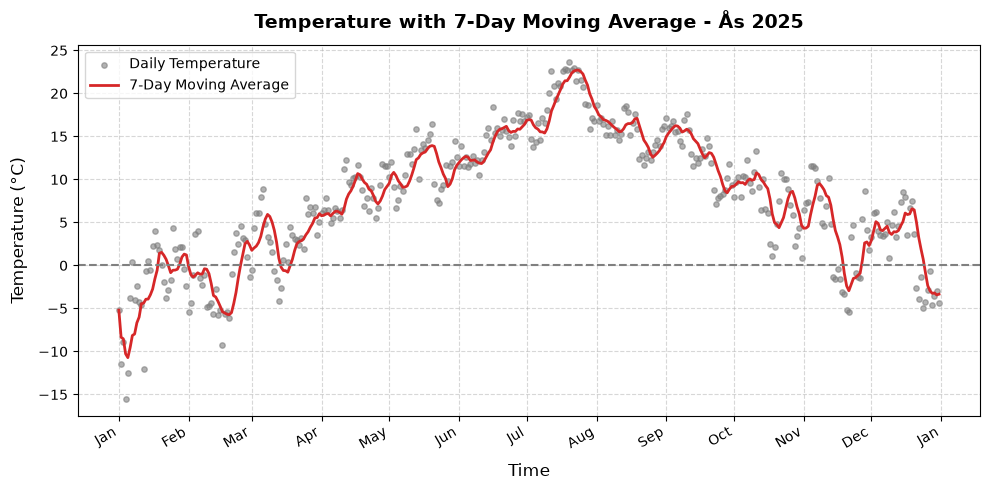

In [38]:
def calculate_moving_average(series: pd.Series, window: int = 7) -> pd.Series:
    """
    Calculates the moving average of a pandas series using panda's rolling function.
    """
    # min_periods=1 allows calculating partial averages for the first (window-1) days
    return series.rolling(window, min_periods=1).mean()


# Use the function we just defined to calculate the moving average temperature
df_temp_2025_mean["temp_7d_avg"] = calculate_moving_average(df_temp_2025_mean["mean_temp"])

# Prepare for plotting
fig, ax = plt.subplots(figsize=(10, 5), dpi=100)

# Daily temperature as scatter points
ax.scatter(
    df_temp_2025_mean.index,
    df_temp_2025_mean["mean_temp"],
    color="#7f7f7f",
    alpha=0.6,
    s=15,
    label="Daily Temperature"
)

# 7-day moving average rendered as a solid line
ax.plot(
    df_temp_2025_mean.index,
    df_temp_2025_mean["temp_7d_avg"],
    color="#d62728",
    linewidth=2.0,
    label="7-Day Moving Average"
)

# Include a horisontal line for temp = 0 degrees Celsius for readability
ax.axhline(y=0, color='gray', linestyle='--')

# Format x-axis to show months
ax.xaxis.set_major_locator(mdates.MonthLocator())  # Major tick at every month start
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))  # Jan, Feb, etc.

# Styling and formatting
ax.set_title("Temperature with 7-Day Moving Average - Ås 2025", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Time", fontsize=12, labelpad=8)
ax.set_ylabel("Temperature (°C)", fontsize=12, labelpad=8)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper left")

fig.autofmt_xdate()
plt.tight_layout()
plt.show()